# L1: Framing the ML Forecasting Problem & Building Baselines

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True


In [10]:
def load_fred_series_local(csv_path: str) -> pd.Series:
    df = pd.read_csv(csv_path)
    # Find date + value columns (FRED usually: DATE + SERIES_CODE)
    date_col = [c for c in df.columns if "DATE" in c.upper()]
    date_col = date_col[0] if date_col else df.columns[0]
    val_col  = [c for c in df.columns if c != date_col][0]

    s = (df.rename(columns={date_col: "date", val_col: "value"})
        .assign(date=lambda d: pd.to_datetime(d["date"]))
        .set_index("date")["value"]
        .sort_index())

    s = pd.to_numeric(s, errors="coerce").asfreq("MS")  # monthly start
    s.name = "china_elec_prod"
    return s

# Load your file saved next to the notebook
y = load_fred_series_local("data/CHNPRENEL01MLM.csv")


Start: 1999-01-01 00:00:00 | End: 2023-11-01 00:00:00 | Nobs: 299 | Freq: MS


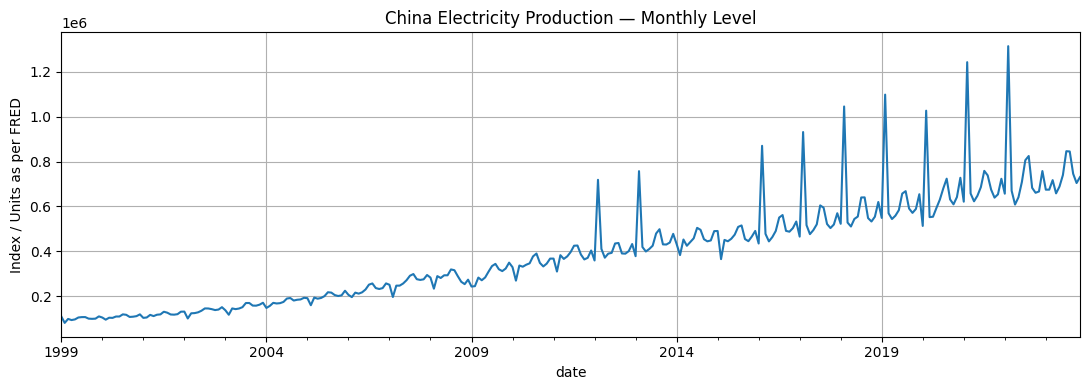

In [11]:
print("Start:", y.index.min(), "| End:", y.index.max(), "| Nobs:", y.notna().sum(), "| Freq:", y.index.freqstr)
y.plot(title="China Electricity Production — Monthly Level")
plt.ylabel("Index / Units as per FRED")
plt.tight_layout()
# plt.savefig("l1_data_overview.png", dpi=140, bbox_inches="tight")
plt.show()


In [12]:
H   = 12   # forecast horizon
m   = 12   # seasonal period (monthly)
VAL = 12   # validation window (set 0 to skip validation)

def time_splits(y: pd.Series, H=12, VAL=12):
    """Return train, validation, test splits by time."""
    test = y.iloc[-H:]
    val  = y.iloc[-(H+VAL):-H] if VAL > 0 else None
    train = y.iloc[:-(H+VAL)] if VAL > 0 else y.iloc[:-H]
    return train, val, test

train, val, test = time_splits(y, H=H, VAL=VAL)
print(f"train={len(train)}, val={0 if val is None else len(val)}, test={len(test)}")


train=275, val=12, test=12


In [13]:
from pandas.tseries.frequencies import to_offset

def _get_offset(idx: pd.DatetimeIndex):
    """Return a DateOffset for idx even if idx.freq is None."""
    if idx.freq is not None:
        return idx.freq
    inferred = pd.infer_freq(idx)
    if inferred is not None:
        return to_offset(inferred)
    # Fallback: use the most common step in the index
    if len(idx) >= 2:
        step = pd.Series(idx[1:] - idx[:-1]).mode().iloc[0]
        return to_offset(step)
    # Last resort (monthly start)
    return to_offset("MS")

def naive_forecast(y_train: pd.Series, H: int) -> pd.Series:
    last = y_train.iloc[-1]
    off  = _get_offset(y_train.index)
    idx  = pd.date_range(y_train.index[-1] + off, periods=H, freq=off)
    return pd.Series(np.repeat(last, H), index=idx, name="naive")

def seasonal_naive_forecast(y_train: pd.Series, H: int, m: int) -> pd.Series:
    history = y_train.copy()
    off     = _get_offset(history.index)
    preds = []
    for _ in range(H):
        preds.append(history.iloc[-m])            # value one season ago
        next_idx = history.index[-1] + off
        history  = pd.concat([history, pd.Series([preds[-1]], index=[next_idx])])
    idx = pd.date_range(y_train.index[-1] + off, periods=H, freq=off)
    return pd.Series(preds, index=idx, name="seasonal_naive")


In [14]:
def rmse(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    return float(np.sqrt(np.mean((y_true - y_pred)**2)))

def mape(y_true, y_pred, eps=1e-8):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    denom = np.maximum(np.abs(y_true), eps)
    return float(np.mean(np.abs((y_true - y_pred)/denom)) * 100)

def smape(y_true, y_pred, eps=1e-8):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    denom = np.maximum((np.abs(y_true) + np.abs(y_pred))/2, eps)
    return float(np.mean(np.abs(y_true - y_pred)/denom) * 100)

def score_forecast(y_true: pd.Series, y_pred: pd.Series) -> dict:
    y_true, y_pred = y_true.align(y_pred, join="inner")
    return {
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "RMSE": rmse(y_true, y_pred),
        "MAPE%": mape(y_true, y_pred),
        "sMAPE%": smape(y_true, y_pred),
    }

def plot_forecast(y_true: pd.Series, preds: dict, title="Forecast vs Actual"):
    ax = y_true.plot(label="actual", color="black", lw=2)
    for name, yhat in preds.items():
        yhat.plot(ax=ax, label=name)
    ax.set_title(title); ax.legend()
    plt.tight_layout()
    # plt.savefig("l1_baseline_plot.png", dpi=140, bbox_inches="tight")
    plt.show()


Validation scores (lower is better):


,MAE,RMSE,MAPE%,sMAPE%
naive,102761.667,203968.188,10.556,12.376
s-naive,28642.083,38412.930,3.553,3.651


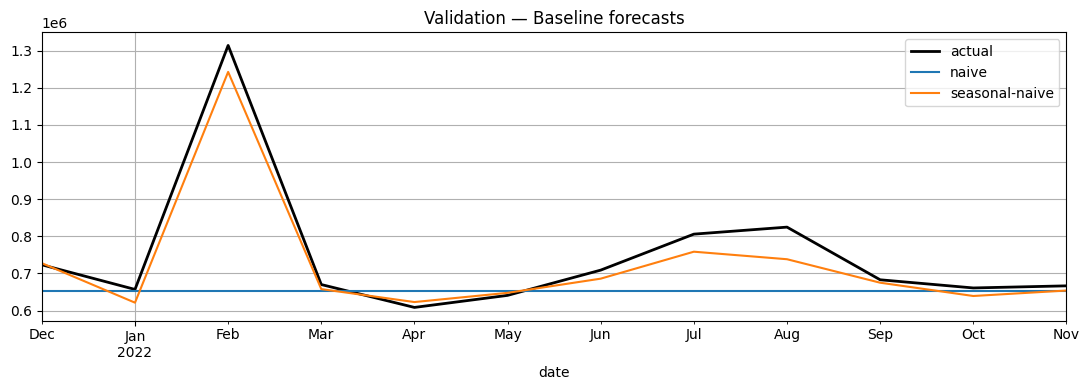

In [15]:
if VAL > 0:
    naive_val  = naive_forecast(train, VAL)
    snaive_val = seasonal_naive_forecast(train, VAL, m=m)
    val_scores = {
        "naive":   score_forecast(val, naive_val),
        "s-naive": score_forecast(val, snaive_val)
    }
    print("Validation scores (lower is better):")
    display(pd.DataFrame(val_scores).T.round(3))
    plot_forecast(val, {"naive": naive_val, "seasonal-naive": snaive_val},
                title="Validation — Baseline forecasts")


Test scores (lower is better):


,MAE,RMSE,MAPE%,sMAPE%
naive,66699.167,87904.524,8.576,9.222
s-naive,91461.667,189286.353,13.134,10.774


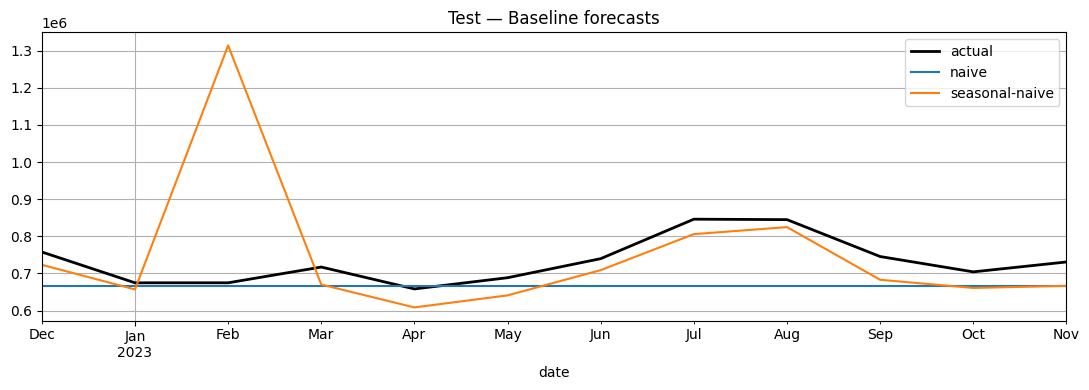

In [16]:
train_plus = pd.concat([train, val]) if VAL > 0 else train

naive_test  = naive_forecast(train_plus, H)
snaive_test = seasonal_naive_forecast(train_plus, H, m=m)

test_scores = {
    "naive":   score_forecast(test, naive_test),
    "s-naive": score_forecast(test, snaive_test)
}
print("Test scores (lower is better):")
display(pd.DataFrame(test_scores).T.round(3))

plot_forecast(test, {"naive": naive_test, "seasonal-naive": snaive_test},
            title="Test — Baseline forecasts")


In [17]:
def seasonal_autocorr(y: pd.Series, lag: int) -> float:
    return float(y.dropna().autocorr(lag=lag))

print("ACF at lag 12:", round(seasonal_autocorr(y, 12), 3))


ACF at lag 12: 0.958


# L2: Feature Engineering for Time Series

Start: 1999-01-01 00:00:00 | End: 2023-11-01 00:00:00 | Nobs: 299 | Freq: MS


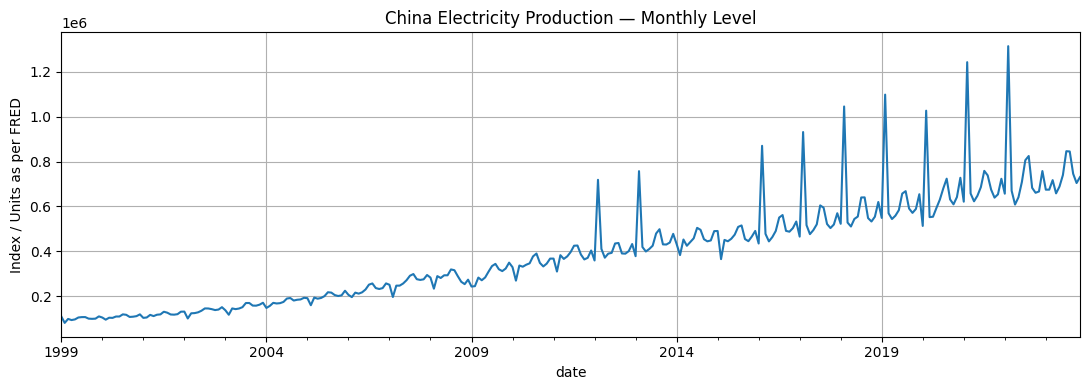

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pandas.tseries.frequencies import to_offset

plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True

def load_fred_series_local(csv_path: str) -> pd.Series:
    df = pd.read_csv(csv_path)
    date_col = [c for c in df.columns if "DATE" in c.upper()]
    date_col = date_col[0] if date_col else df.columns[0]
    val_col  = [c for c in df.columns if c != date_col][0]
    s = (df.rename(columns={date_col: "date", val_col: "value"})
        .assign(date=lambda d: pd.to_datetime(d["date"]))
        .set_index("date")["value"]
        .sort_index())
    s = pd.to_numeric(s, errors="coerce").asfreq("MS")  # monthly start
    s.name = "china_elec_prod"
    return s

y = load_fred_series_local("data/CHNPRENEL01MLM.csv")
print("Start:", y.index.min(), "| End:", y.index.max(), "| Nobs:", y.notna().sum(), "| Freq:", y.index.freqstr)

ax = y.plot(title="China Electricity Production — Monthly Level")
ax.set_ylabel("Index / Units as per FRED")
plt.tight_layout()
# plt.savefig("L2_series_overview.png", dpi=140, bbox_inches="tight")
plt.show()


In [19]:
H   = 12   # forecast horizon (months ahead)
VAL = 12   # validation window length (months)
m   = 12   # seasonal period (monthly)

def time_splits(y: pd.Series, H=12, VAL=12):
    test = y.iloc[-H:]
    val  = y.iloc[-(H+VAL):-H] if VAL > 0 else None
    train = y.iloc[:-(H+VAL)] if VAL > 0 else y.iloc[:-H]
    return train, val, test

train, val, test = time_splits(y, H=H, VAL=VAL)
print(f"train={len(train)}, val={0 if val is None else len(val)}, test={len(test)}")


train=275, val=12, test=12


In [20]:
def add_lags(df: pd.DataFrame, col: str, lags=(1, 12)):
    for L in lags:
        df[f"{col}_lag{L}"] = df[col].shift(L)
    return df

def add_rolls(df: pd.DataFrame, col: str, windows=(3, 12), stats=("mean","std","min","max","median")):
    # shift(1) to ensure each rolling window ends at t-1
    shifted = df[col].shift(1)
    for w in windows:
        r = shifted.rolling(window=w, min_periods=w)
        if "mean"   in stats: df[f"{col}_r{w}_mean"]   = r.mean()
        if "std"    in stats: df[f"{col}_r{w}_std"]    = r.std(ddof=0)
        if "min"    in stats: df[f"{col}_r{w}_min"]    = r.min()
        if "max"    in stats: df[f"{col}_r{w}_max"]    = r.max()
        if "median" in stats: df[f"{col}_r{w}_median"] = r.median()
    return df

def add_calendar(df: pd.DataFrame, index: pd.DatetimeIndex, add_onehot=True, add_cyclical=True):
    df["month"]   = index.month
    df["quarter"] = index.quarter
    if add_cyclical:
        df["month_sin"] = np.sin(2*np.pi*df["month"]/12.0)
        df["month_cos"] = np.cos(2*np.pi*df["month"]/12.0)
    if add_onehot:
        dummies = pd.get_dummies(df["month"].astype(int), prefix="m", drop_first=True)
        df[dummies.columns] = dummies
    return df

def align_exog(exog: pd.DataFrame, lag=1, roll_windows=()):
    """Lag exogenous drivers and (optionally) add rolling stats (past-only)."""
    Z = exog.copy().shift(lag)
    for col in exog.columns:
        base = Z[col]
        for w in roll_windows:
            Z[f"{col}_r{w}_mean"] = base.rolling(w, min_periods=w).mean()
    return Z

def make_features(y: pd.Series,
                lags=(1, 12),
                roll_windows=(3, 12),
                add_month_onehot=True,
                add_month_cyc=True,
                exog: pd.DataFrame=None):
    """
    Returns (X, y_aligned) with leakage-safe features and no NaNs.
    """
    df = pd.DataFrame({"y": y})
    df = add_lags(df, "y", lags=lags)
    df = add_rolls(df, "y", windows=roll_windows, stats=("mean","std","min","max","median"))
    df = add_calendar(df, df.index, add_onehot=add_month_onehot, add_cyclical=add_month_cyc)
    if exog is not None:
        Z = align_exog(exog, lag=1, roll_windows=())
        df = df.join(Z, how="left")
    df = df.dropna()
    X = df.drop(columns=["y"])
    y_out = df["y"]
    return X, y_out


In [21]:
X_all, y_all = make_features(
    y,
    lags=(1, 12),           # recent & seasonal
    roll_windows=(3, 12),   # short & seasonal smoothing
    add_month_onehot=True,
    add_month_cyc=True,     # you can toggle this off if you prefer only one-hot
    exog=None
)

print(X_all.shape, y_all.shape)
display(X_all.tail())


(287, 27) (287,)


,y_lag1,y_lag12,y_r3_mean,y_r3_std,y_r3_min,y_r3_max,y_r3_median,y_r12_mean,y_r12_std,y_r12_min,...,m_3,m_4,m_5,m_6,m_7,m_8,m_9,m_10,m_11,m_12
date,,,,,,,,,,,,,,,,,,,,,
2023-07-01,739900.0,805920.0,695610.000000,33661.712177,658350.0,739900.0,688580.0,712757.500000,54869.680133,658350.0,...,False,False,False,False,True,False,False,False,False,False
2023-08-01,846170.0,824800.0,758216.666667,65626.606562,688580.0,846170.0,739900.0,716111.666667,61313.959882,658350.0,...,False,False,False,False,False,True,False,False,False,False
2023-09-01,844990.0,683000.0,810353.333333,49820.358846,739900.0,846170.0,844990.0,717794.166667,64469.192540,658350.0,...,False,False,False,False,False,False,True,False,False,False
2023-10-01,745610.0,661000.0,812256.666667,47128.772057,745610.0,846170.0,844990.0,723011.666667,63973.783899,658350.0,...,False,False,False,False,False,False,False,True,False,False
2023-11-01,704350.0,666670.0,764983.333333,59027.659806,704350.0,844990.0,745610.0,726624.166667,61548.049957,658350.0,...,False,False,False,False,False,False,False,False,True,False


In [22]:
def split_after_fe(X, y, H=12, VAL=12):
    """
    Align X and y by their common DatetimeIndex, drop any rows with NaNs,
    then create train/val/test splits by time (no leakage).
    """
    # 1) Align by index intersection (explicit & robust)
    idx = X.index.intersection(y.index)
    X = X.loc[idx].sort_index()
    y = y.loc[idx].sort_index()

    # 2) Drop any rows where X has NaNs or y is NaN (can happen after FE)
    bad = X.isna().any(axis=1) | ~y.notna()
    if bad.any():
        X = X.loc[~bad]
        y = y.loc[~bad]

    # 3) Sanity checks
    n = len(X)
    assert n == len(y), "X and y must be the same length after alignment"
    assert H > 0 and (VAL >= 0), "H must be >0; VAL must be >=0"
    assert H + max(VAL, 0) < n, "Not enough rows for the requested H and VAL"

    # 4) Time-ordered splits (validation is optional)
    test_X, test_y = X.iloc[-H:], y.iloc[-H:]
    if VAL > 0:
        val_X,  val_y  = X.iloc[-(H+VAL):-H], y.iloc[-(H+VAL):-H]
        train_X,train_y = X.iloc[:-(H+VAL)],  y.iloc[:-(H+VAL)]
    else:
        val_X,  val_y  = None, None
        train_X,train_y = X.iloc[:-H], y.iloc[:-H]

    return (train_X, train_y), (val_X, val_y), (test_X, test_y)


In [24]:
(train_X, train_y), (val_X, val_y), (test_X, test_y) = split_after_fe(X_all, y_all, H=H, VAL=VAL)
print("Train:", train_X.shape, "| Val:", None if val_X is None else val_X.shape, "| Test:", test_X.shape)


Train: (263, 27) | Val: (12, 27) | Test: (12, 27)


In [25]:
corrs = train_X.assign(y=train_y).corr(numeric_only=True)["y"].sort_values(ascending=False)
display(corrs.to_frame("corr_with_y").head(10))


,corr_with_y
y,1.000000
y_lag12,0.967093
y_r12_median,0.916298
y_r12_mean,0.915185
y_r12_min,0.910832
y_r3_min,0.909132
y_r3_median,0.900878
y_r3_mean,0.875774
y_r12_max,0.873590
y_lag1,0.820252


In [26]:
import numpy as np

num_cols = train_X.select_dtypes(include=[np.number]).columns
train_X[num_cols].describe().T


,count,mean,std,min,25%,50%,75%,max
y_lag1,263.0,3.695587e+05,201675.242823,95740.000000,195125.000000,3.593650e+05,497315.000000,1.242770e+06
y_lag12,263.0,3.432595e+05,190828.209143,81410.000000,172955.000000,3.295000e+05,477302.145000,1.098190e+06
y_r3_mean,263.0,3.674627e+05,189318.714098,101283.333333,193015.000000,3.536233e+05,501175.833333,8.639583e+05
y_r3_std,263.0,3.473630e+04,59908.316351,890.954544,6585.418506,1.435574e+04,30362.483827,2.847076e+05
y_r3_min,263.0,3.338585e+05,161260.717482,95740.000000,189210.000000,3.328800e+05,457159.170000,6.860500e+05
y_r3_max,263.0,4.123412e+05,250708.139346,104390.000000,197365.000000,3.776400e+05,547470.000000,1.242770e+06
y_r3_median,263.0,3.561885e+05,172577.209510,100300.000000,192470.000000,3.663800e+05,491280.000000,7.383500e+05
y_r12_mean,263.0,3.568969e+05,182441.505403,100573.333333,186787.083333,3.416192e+05,503669.579167,7.216654e+05
y_r12_std,263.0,5.633726e+04,53301.650544,4223.331689,13238.214164,2.912282e+04,111173.577124,1.767703e+05
y_r12_min,263.0,2.997823e+05,152488.392951,81410.000000,160110.000000,2.695900e+05,435085.000000,6.213850e+05


In [28]:
# y_log = np.log(y.clip(lower=1e-8))
# X_all_log, y_all_log = make_features(
#     y_log, lags=(1,12), roll_windows=(3,12),
#     add_month_onehot=True, add_month_cyc=True
# )
# (train_X_log, train_y_log), (val_X_log, val_y_log), (test_X_log, test_y_log) = split_after_fe(
#     X_all_log, y_all_log, H=H, VAL=VAL
# )

# (Optional) Log transform variant
# If your variance grows with the level, try modeling log(y) instead of y. If you do, create lags/rolls on the log scale too:


# L3: Minimal ML Baseline with Ridge (Pipelines + Time-Aware CV)

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pandas.tseries.frequencies import to_offset
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error

plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True

# --- Re-load series (Lesson 1) ---
def load_fred_series_local(csv_path: str) -> pd.Series:
    df = pd.read_csv(csv_path)
    date_col = [c for c in df.columns if "DATE" in c.upper()]
    date_col = date_col[0] if date_col else df.columns[0]
    val_col  = [c for c in df.columns if c != date_col][0]
    s = (df.rename(columns={date_col: "date", val_col: "value"})
           .assign(date=lambda d: pd.to_datetime(d["date"]))
           .set_index("date")["value"]
           .sort_index())
    s = pd.to_numeric(s, errors="coerce").asfreq("MS")
    s.name = "china_elec_prod"
    return s

y = load_fred_series_local("data/CHNPRENEL01MLM.csv")

# --- Feature builders (Lesson 2) ---
def add_lags(df: pd.DataFrame, col: str, lags=(1, 12)):
    for L in lags:
        df[f"{col}_lag{L}"] = df[col].shift(L)
    return df

def add_rolls(df: pd.DataFrame, col: str, windows=(3, 12), stats=("mean","std","min","max","median")):
    shifted = df[col].shift(1)  # stops at t-1
    for w in windows:
        r = shifted.rolling(window=w, min_periods=w)
        if "mean"   in stats: df[f"{col}_r{w}_mean"]   = r.mean()
        if "std"    in stats: df[f"{col}_r{w}_std"]    = r.std(ddof=0)
        if "min"    in stats: df[f"{col}_r{w}_min"]    = r.min()
        if "max"    in stats: df[f"{col}_r{w}_max"]    = r.max()
        if "median" in stats: df[f"{col}_r{w}_median"] = r.median()
    return df

def add_calendar(df: pd.DataFrame, index: pd.DatetimeIndex, add_onehot=True, add_cyclical=True):
    df["month"]   = index.month
    df["quarter"] = index.quarter
    if add_cyclical:
        df["month_sin"] = np.sin(2*np.pi*df["month"]/12.0)
        df["month_cos"] = np.cos(2*np.pi*df["month"]/12.0)
    if add_onehot:
        dummies = pd.get_dummies(df["month"].astype(int), prefix="m", drop_first=True)
        df[dummies.columns] = dummies
    return df

def make_features(y: pd.Series,
                  lags=(1, 12),
                  roll_windows=(3, 12),
                  add_month_onehot=True,
                  add_month_cyc=True,
                  exog: pd.DataFrame=None):
    df = pd.DataFrame({"y": y})
    df = add_lags(df, "y", lags=lags)
    df = add_rolls(df, "y", windows=roll_windows, stats=("mean","std","min","max","median"))
    df = add_calendar(df, df.index, add_onehot=add_month_onehot, add_cyclical=add_month_cyc)
    if exog is not None:
        Z = exog.copy().shift(1)  # lag exogenous
        df = df.join(Z, how="left")
    df = df.dropna()
    return df.drop(columns=["y"]), df["y"]

# Build compact feature set
LAGS  = (1, 12)
ROLLS = (3, 12)
X_all, y_all = make_features(y, lags=LAGS, roll_windows=ROLLS, add_month_onehot=True, add_month_cyc=True)

# Split after FE (Lesson 2)
def split_after_fe(X, y, H=12, VAL=12):
    idx = X.index.intersection(y.index)
    X = X.loc[idx].sort_index()
    y = y.loc[idx].sort_index()
    bad = X.isna().any(axis=1) | ~y.notna()
    if bad.any():
        X = X.loc[~bad]; y = y.loc[~bad]
    n = len(X)
    assert H > 0 and VAL >= 0 and (H + VAL) < n
    test_X, test_y = X.iloc[-H:], y.iloc[-H:]
    if VAL > 0:
        val_X,  val_y  = X.iloc[-(H+VAL):-H], y.iloc[-(H+VAL):-H]
        train_X,train_y = X.iloc[:-(H+VAL)],  y.iloc[:-(H+VAL)]
    else:
        val_X, val_y = None, None
        train_X,train_y = X.iloc[:-H], y.iloc[:-H]
    return (train_X, train_y), (val_X, val_y), (test_X, test_y)

H, VAL, m = 12, 12, 12
(train_X, train_y), (val_X, val_y), (test_X, test_y) = split_after_fe(X_all, y_all, H=H, VAL=VAL)


In [36]:
# Identify one-hot month dummy columns by prefix 'm_'
month_dummy_cols = [c for c in train_X.columns if c.startswith("m_")]
num_cols = [c for c in train_X.columns if c not in month_dummy_cols]

pre = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("mon", "passthrough", month_dummy_cols),
    ],
    remainder="drop"
)

ridge = Ridge(random_state=0)

pipe = Pipeline([
    ("pre", pre),
    ("model", ridge)
])

# Time-aware CV
tscv = TimeSeriesSplit(n_splits=5)
param_grid = {"model__alpha": np.logspace(-3, 3, 7)}  # 0.001 .. 1000

gcv = GridSearchCV(
    estimator=pipe,
    param_grid=param_grid,
    cv=tscv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

gcv.fit(train_X, train_y)
best = gcv.best_estimator_
print("Best alpha:", gcv.best_params_)

Best alpha: {'model__alpha': np.float64(0.1)}


In [37]:
def rmse(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    return float(np.sqrt(np.mean((y_true - y_pred)**2)))

def score_df(y_true: pd.Series, y_pred: pd.Series, name: str):
    y_true, y_pred = y_true.align(y_pred, join="inner")
    out = pd.DataFrame({
        "Model": [name],
        "MAE": [mean_absolute_error(y_true, y_pred)],
        "RMSE": [rmse(y_true, y_pred)]
    })
    return out

scores = []

# Validation (if you kept a VAL window)
if val_X is not None:
    val_pred = pd.Series(best.predict(val_X), index=val_X.index, name="ridge_val")
    scores.append(score_df(val_y, val_pred, "Ridge (val, one-step)"))

# Test (one-step)
test_pred_onestep = pd.Series(best.predict(test_X), index=test_X.index, name="ridge_test_one_step")
scores.append(score_df(test_y, test_pred_onestep, "Ridge (test, one-step)"))

pd.concat(scores, ignore_index=True).round(3)


,Model,MAE,RMSE
0,"Ridge (val, one-step)",36003.256,42994.502
1,"Ridge (test, one-step)",65953.977,177409.929


In [38]:
# Offset helper (works even if index.freq is None)
def _get_offset(idx: pd.DatetimeIndex):
    if idx.freq is not None:
        return idx.freq
    inferred = pd.infer_freq(idx)
    if inferred is not None:
        return to_offset(inferred)
    if len(idx) >= 2:
        step = pd.Series(idx[1:] - idx[:-1]).mode().iloc[0]
        return to_offset(step)
    return to_offset("MS")

def recursive_forecast(pipe, y_hist: pd.Series, H: int,
                       lags=LAGS, rolls=ROLLS,
                       add_month_onehot=True, add_month_cyc=True,
                       columns_ref=None) -> pd.Series:
    """Roll a one-step model H times forward, reusing Lesson 2 features each step."""
    preds = []
    off = _get_offset(y_hist.index)

    # We build features from y_hist each step and align columns to training columns
    for _ in range(H):
        X_tmp, _ = make_features(y_hist, lags=lags, roll_windows=rolls,
                                 add_month_onehot=add_month_onehot, add_month_cyc=add_month_cyc)
        x_next = X_tmp.iloc[[-1]]

        # Align columns to training feature set if provided
        if columns_ref is not None:
            missing = [c for c in columns_ref if c not in x_next.columns]
            for c in missing:
                x_next[c] = 0.0
            x_next = x_next[columns_ref]

        y_hat = pipe.predict(x_next)[0]
        preds.append(y_hat)
        y_hist = pd.concat([y_hist, pd.Series([y_hat], index=[y_hist.index[-1] + off])])

    idx = pd.date_range(start=y_hist.index[-1] - (H-1)*off, periods=H, freq=off)
    return pd.Series(preds, index=idx, name="ridge_recursive")


In [39]:
train_plus_y = pd.concat([train_y, val_y]) if val_y is not None else train_y
ridge_rec = recursive_forecast(best, y_hist=train_plus_y, H=H,
                               lags=LAGS, rolls=ROLLS,
                               columns_ref=train_X.columns)

# Baselines from Lesson 1 (safe versions)
def naive_forecast(y_train: pd.Series, H: int) -> pd.Series:
    last = y_train.iloc[-1]
    off  = _get_offset(y_train.index)
    idx  = pd.date_range(y_train.index[-1] + off, periods=H, freq=off)
    return pd.Series(np.repeat(last, H), index=idx, name="naive")

def seasonal_naive_forecast(y_train: pd.Series, H: int, m: int) -> pd.Series:
    history = y_train.copy()
    off     = _get_offset(history.index)
    preds = []
    for _ in range(H):
        preds.append(history.iloc[-m])
        history = pd.concat([history, pd.Series([preds[-1]], index=[history.index[-1] + off])])
    idx = pd.date_range(history.index[-H], periods=H, freq=off)
    return pd.Series(preds, index=idx, name="seasonal_naive")

naive_test  = naive_forecast(train_plus_y, H)
snaive_test = seasonal_naive_forecast(train_plus_y, H, m=12)

# Score on the test horizon
def score(y_true, y_pred, name):
    y_true, y_pred = y_true.align(y_pred, join="inner")
    return {
        "Model": name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": float(np.sqrt(np.mean((y_true.values - y_pred.values)**2)))
    }

cmp = pd.DataFrame([
    score(test_y, ridge_rec,   "Ridge (test, recursive)"),
    score(test_y, naive_test,  "Naïve"),
    score(test_y, snaive_test, "Seasonal-Naïve")
]).round(3)
cmp


,Model,MAE,RMSE
0,"Ridge (test, recursive)",98125.731,177376.463
1,Naïve,66699.167,87904.524
2,Seasonal-Naïve,91461.667,189286.353


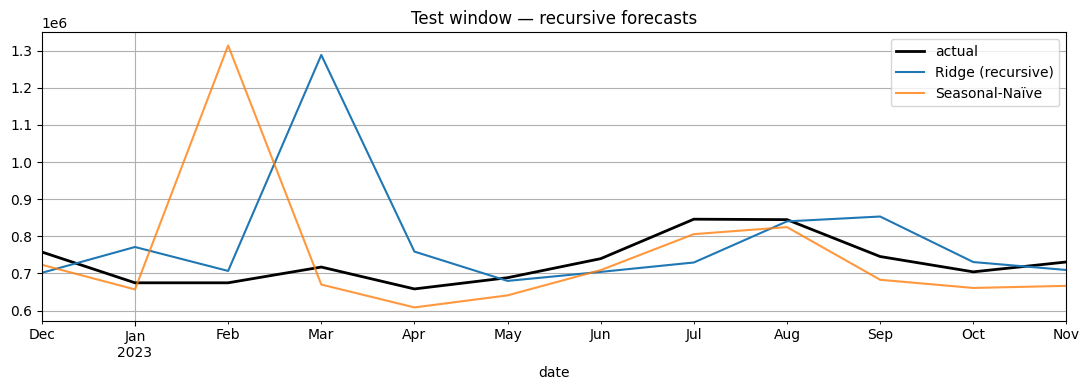

In [40]:
ax = test_y.plot(label="actual", color="black", lw=2)
ridge_rec.plot(ax=ax, label="Ridge (recursive)")
snaive_test.plot(ax=ax, label="Seasonal-Naïve", alpha=0.8)
plt.title("Test window — recursive forecasts")
plt.legend(); plt.tight_layout()
# plt.savefig("L3_recursive_cmp.png", dpi=140, bbox_inches="tight")
plt.show()


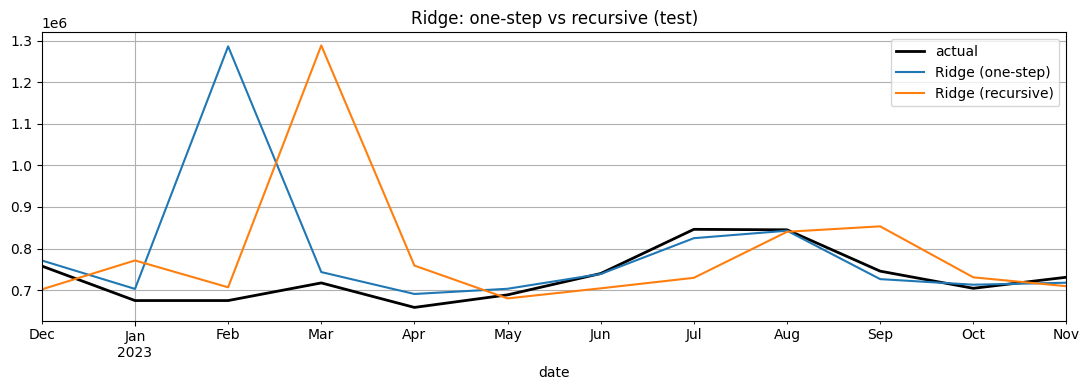

In [41]:
ax = test_y.plot(label="actual", color="black", lw=2)
test_pred_onestep.plot(ax=ax, label="Ridge (one-step)")
ridge_rec.plot(ax=ax, label="Ridge (recursive)")
plt.title("Ridge: one-step vs recursive (test)")
plt.legend(); plt.tight_layout()
# plt.savefig("L3_ridge_one_vs_rec.png", dpi=140, bbox_inches="tight")
plt.show()


# L4: Tree-Based Models for Time-Series: Random Forest

In [43]:
from pandas.tseries.frequencies import to_offset
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.inspection import permutation_importance


# Identify month dummies (prefix 'm_') to keep awareness, but pass everything through
month_dummy_cols = [c for c in train_X.columns if c.startswith("m_")]
num_cols = [c for c in train_X.columns if c not in month_dummy_cols]

pre = ColumnTransformer(
    transformers=[
        ("num", "passthrough", num_cols),
        ("mon", "passthrough", month_dummy_cols),
    ],
    remainder="drop"
)

rf = RandomForestRegressor(random_state=42, n_estimators=300, n_jobs=-1)

pipe_rf = Pipeline([
    ("pre", pre),
    ("model", rf)
])


In [44]:
tscv = TimeSeriesSplit(n_splits=5)

param_grid = {
    "model__n_estimators": [300],         # fixed (reduce variance)
    "model__max_depth": [None, 8, 12],
    "model__min_samples_leaf": [1, 3, 5],
    "model__max_features": ["sqrt", 0.5]  # try sqrt or 50% of features
}

gcv_rf = GridSearchCV(
    estimator=pipe_rf,
    param_grid=param_grid,
    cv=tscv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

gcv_rf.fit(train_X, train_y)
best_rf = gcv_rf.best_estimator_
print("Best params:", gcv_rf.best_params_)


Best params: {'model__max_depth': None, 'model__max_features': 0.5, 'model__min_samples_leaf': 1, 'model__n_estimators': 300}


In [45]:
def rmse(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    return float(np.sqrt(np.mean((y_true - y_pred)**2)))

def score_df(y_true: pd.Series, y_pred: pd.Series, name: str):
    y_true, y_pred = y_true.align(y_pred, join="inner")
    return pd.DataFrame({"Model":[name],
                         "MAE":[mean_absolute_error(y_true, y_pred)],
                         "RMSE":[rmse(y_true, y_pred)]})

scores = []
if val_X is not None:
    val_pred_rf = pd.Series(best_rf.predict(val_X), index=val_X.index, name="rf_val_onestep")
    scores.append(score_df(val_y, val_pred_rf, "RF (val, one-step)"))

test_pred_rf_onestep = pd.Series(best_rf.predict(test_X), index=test_X.index, name="rf_test_onestep")
scores.append(score_df(test_y, test_pred_rf_onestep, "RF (test, one-step)"))

pd.concat(scores, ignore_index=True).round(3)


,Model,MAE,RMSE
0,"RF (val, one-step)",48670.217,69466.948
1,"RF (test, one-step)",58920.854,136666.563


In [46]:
def recursive_forecast(pipe, y_hist: pd.Series, H: int,
                       lags=LAGS, rolls=ROLLS,
                       add_month_onehot=True, add_month_cyc=True,
                       columns_ref=None) -> pd.Series:
    preds = []
    off = _get_offset(y_hist.index)
    for _ in range(H):
        X_tmp, _ = make_features(y_hist, lags=lags, roll_windows=rolls,
                                 add_month_onehot=add_month_onehot, add_month_cyc=add_month_cyc)
        x_next = X_tmp.iloc[[-1]]
        if columns_ref is not None:
            missing = [c for c in columns_ref if c not in x_next.columns]
            for c in missing:
                x_next[c] = 0.0
            x_next = x_next[columns_ref]
        y_hat = pipe.predict(x_next)[0]
        preds.append(y_hat)
        y_hist = pd.concat([y_hist, pd.Series([y_hat], index=[y_hist.index[-1] + off])])
    idx = pd.date_range(start=y_hist.index[-1] - (H-1)*off, periods=H, freq=off)
    return pd.Series(preds, index=idx, name="rf_recursive")

# Baselines (safe helpers)
def naive_forecast(y_train: pd.Series, H: int) -> pd.Series:
    last = y_train.iloc[-1]
    off  = _get_offset(y_train.index)
    idx  = pd.date_range(y_train.index[-1] + off, periods=H, freq=off)
    return pd.Series(np.repeat(last, H), index=idx, name="naive")

def seasonal_naive_forecast(y_train: pd.Series, H: int, m: int) -> pd.Series:
    history = y_train.copy()
    off     = _get_offset(history.index)
    preds = []
    for _ in range(H):
        preds.append(history.iloc[-m])
        history = pd.concat([history, pd.Series([preds[-1]], index=[history.index[-1] + off])])
    idx = pd.date_range(history.index[-H], periods=H, freq=off)
    return pd.Series(preds, index=idx, name="seasonal_naive")

# Roll from end of Train+Val
train_plus_y = pd.concat([train_y, val_y]) if val_y is not None else train_y
rf_rec  = recursive_forecast(best_rf, y_hist=train_plus_y, H=H, columns_ref=train_X.columns)
naive_t = naive_forecast(train_plus_y, H)
snaive_t= seasonal_naive_forecast(train_plus_y, H, m=12)

def score(y_true, y_pred, name):
    y_true, y_pred = y_true.align(y_pred, join="inner")
    return {"Model": name,
            "MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": float(np.sqrt(np.mean((y_true.values - y_pred.values)**2)))}

cmp = pd.DataFrame([
    score(test_y, rf_rec,  "RF (test, recursive)"),
    score(test_y, naive_t, "Naïve"),
    score(test_y, snaive_t,"Seasonal-Naïve"),
]).round(3)
cmp


,Model,MAE,RMSE
0,"RF (test, recursive)",90173.412,135162.586
1,Naïve,66699.167,87904.524
2,Seasonal-Naïve,91461.667,189286.353


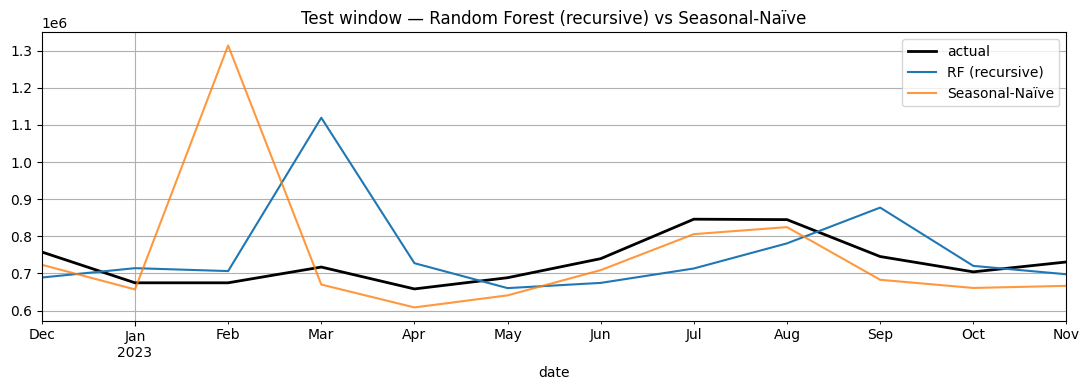

In [47]:
ax = test_y.plot(label="actual", color="black", lw=2)
rf_rec.plot(ax=ax, label="RF (recursive)")
snaive_t.plot(ax=ax, label="Seasonal-Naïve", alpha=0.8)
plt.title("Test window — Random Forest (recursive) vs Seasonal-Naïve")
plt.legend(); plt.tight_layout()
# plt.savefig("L4_rf_recursive_cmp.png", dpi=140, bbox_inches="tight")
plt.show()


Top features by permutation importance on validation:


,feature,importance_mean,importance_std
0,y_lag12,0.670713,0.182265
1,m_2,0.231056,0.067905
2,month,0.011804,0.004566
3,month_sin,0.005355,0.003628
4,y_lag1,0.005040,0.003340
5,m_8,0.003227,0.001082
6,y_r3_max,0.002380,0.002375
7,y_r3_mean,0.001728,0.000907
8,m_7,0.001688,0.000734
9,quarter,0.001634,0.000910


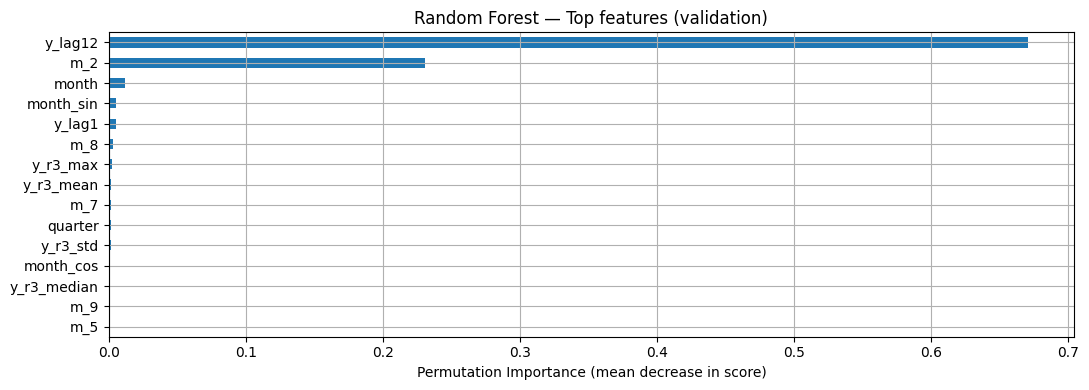

In [48]:
# Make sure these are imported earlier
from sklearn.inspection import permutation_importance
from IPython.display import display

# Choose a split to evaluate importance on (prefer validation to avoid peeking at test)
use_X = val_X if val_X is not None else test_X
use_y = val_y if val_X is not None else test_y
split_name = "validation" if val_X is not None else "test"

assert use_X is not None and use_y is not None, "Need val_X/val_y or test_X/test_y."

# Compute permutation importance
r = permutation_importance(
    best_rf,                  # your tuned RandomForest pipeline
    use_X, use_y,
    n_repeats=20,
    random_state=42,
    n_jobs=-1
)

imp = (pd.DataFrame({
        "feature": use_X.columns,
        "importance_mean": r.importances_mean,
        "importance_std":  r.importances_std
      })
      .sort_values("importance_mean", ascending=False))

print(f"Top features by permutation importance on {split_name}:")
display(imp.head(15).reset_index(drop=True))

# Optional: horizontal bar plot
topk = imp.head(15).sort_values("importance_mean")  # ascending for barh
ax = topk.plot(kind="barh", x="feature", y="importance_mean", legend=False)
ax.set_xlabel("Permutation Importance (mean decrease in score)")
ax.set_ylabel("")
ax.set_title(f"Random Forest — Top features ({split_name})")
plt.tight_layout()
# plt.savefig("L4_rf_permutation_importance.png", dpi=140, bbox_inches="tight")
plt.show()


In [49]:
if 'ridge_rec' in globals():
    cmp2 = pd.DataFrame([
        score(test_y, ridge_rec, "Ridge (recursive)"),
        score(test_y, rf_rec,    "RF (recursive)"),
        score(test_y, snaive_t,  "Seasonal-Naïve")
    ]).round(3)
    cmp2


# L5: Put It All Together: Benchmark, Backtest & Hand-Off

In [59]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pandas.tseries.frequencies import to_offset
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True

# ---------- Data loader ----------
def load_fred_series_local(csv_path: str) -> pd.Series:
    df = pd.read_csv(csv_path)
    date_col = [c for c in df.columns if "DATE" in c.upper()]
    date_col = date_col[0] if date_col else df.columns[0]
    val_col  = [c for c in df.columns if c != date_col][0]
    s = (df.rename(columns={date_col: "date", val_col: "value"})
           .assign(date=lambda d: pd.to_datetime(d["date"]))
           .set_index("date")["value"]
           .sort_index())
    s = pd.to_numeric(s, errors="coerce").asfreq("MS")  # monthly start
    s.name = "china_elec_prod"
    return s

# ---------- Feature engineering (leakage-safe) ----------
def add_lags(df: pd.DataFrame, col: str, lags=(1, 12)):
    for L in lags: df[f"{col}_lag{L}"] = df[col].shift(L)
    return df

def add_rolls(df: pd.DataFrame, col: str, windows=(3, 12), stats=("mean","std","min","max","median")):
    shifted = df[col].shift(1)  # window ends at t-1 (no peek)
    for w in windows:
        r = shifted.rolling(window=w, min_periods=w)
        if "mean"   in stats: df[f"{col}_r{w}_mean"]   = r.mean()
        if "std"    in stats: df[f"{col}_r{w}_std"]    = r.std(ddof=0)
        if "min"    in stats: df[f"{col}_r{w}_min"]    = r.min()
        if "max"    in stats: df[f"{col}_r{w}_max"]    = r.max()
        if "median" in stats: df[f"{col}_r{w}_median"] = r.median()
    return df

def add_calendar(df: pd.DataFrame, index: pd.DatetimeIndex, add_onehot=True, add_cyclical=True):
    df["month"] = index.month
    df["quarter"] = index.quarter
    if add_cyclical:
        df["month_sin"] = np.sin(2*np.pi*df["month"]/12.0)
        df["month_cos"] = np.cos(2*np.pi*df["month"]/12.0)
    if add_onehot:
        dummies = pd.get_dummies(df["month"].astype(int), prefix="m", drop_first=True)
        df[dummies.columns] = dummies
    return df

def make_features(y: pd.Series,
                  lags=(1, 12),
                  roll_windows=(3, 12),
                  add_month_onehot=True,
                  add_month_cyc=True,
                  exog: pd.DataFrame=None):
    df = pd.DataFrame({"y": y})
    df = add_lags(df, "y", lags=lags)
    df = add_rolls(df, "y", windows=roll_windows, stats=("mean","std","min","max","median"))
    df = add_calendar(df, df.index, add_onehot=add_month_onehot, add_cyclical=add_month_cyc)
    if exog is not None:
        Z = exog.copy().shift(1)   # lag exogenous to avoid leakage
        df = df.join(Z, how="left")
    df = df.dropna()
    return df.drop(columns=["y"]), df["y"]

def split_after_fe(X, y, H=12, VAL=12):
    idx = X.index.intersection(y.index)
    X = X.loc[idx].sort_index()
    y = y.loc[idx].sort_index()
    bad = X.isna().any(axis=1) | ~y.notna()
    if bad.any():
        X = X.loc[~bad]; y = y.loc[~bad]
    n = len(X)
    assert H > 0 and VAL >= 0 and (H + VAL) < n
    test_X, test_y = X.iloc[-H:], y.iloc[-H:]
    if VAL > 0:
        val_X,  val_y  = X.iloc[-(H+VAL):-H], y.iloc[-(H+VAL):-H]
        train_X,train_y = X.iloc[:-(H+VAL)],  y.iloc[:-(H+VAL)]
    else:
        val_X, val_y = None, None
        train_X,train_y = X.iloc[:-H], y.iloc[:-H]
    return (train_X, train_y), (val_X, val_y), (test_X, test_y)

# ---------- Offsets & baselines ----------
def _get_offset(idx: pd.DatetimeIndex):
    if idx.freq is not None: return idx.freq
    inferred = pd.infer_freq(idx)
    if inferred is not None: return to_offset(inferred)
    if len(idx) >= 2:
        step = pd.Series(idx[1:] - idx[:-1]).mode().iloc[0]
        return to_offset(step)
    return to_offset("MS")

def naive_forecast(y_train: pd.Series, H: int) -> pd.Series:
    last = y_train.iloc[-1]; off = _get_offset(y_train.index)
    idx = pd.date_range(y_train.index[-1] + off, periods=H, freq=off)
    return pd.Series(np.repeat(last, H), index=idx, name="Naïve")

def seasonal_naive_forecast(y_train: pd.Series, H: int, m: int) -> pd.Series:
    history = y_train.copy(); off = _get_offset(history.index)
    preds = []
    for _ in range(H):
        preds.append(history.iloc[-m])
        history = pd.concat([history, pd.Series([preds[-1]], index=[history.index[-1] + off])])
    idx = pd.date_range(history.index[-H], periods=H, freq=off)
    return pd.Series(preds, index=idx, name="Seasonal-Naïve")

# ---------- Recursive forecasting wrapper ----------
def recursive_forecast(pipe, y_hist: pd.Series, H: int,
                       fe_kwargs: dict,
                       columns_ref=None,
                       name="model") -> pd.Series:
    preds = []
    off = _get_offset(y_hist.index)
    for _ in range(H):
        X_tmp, _ = make_features(y_hist, **fe_kwargs)
        x_next = X_tmp.iloc[[-1]]
        if columns_ref is not None:
            missing = [c for c in columns_ref if c not in x_next.columns]
            for c in missing: x_next[c] = 0.0
            x_next = x_next[columns_ref]
        y_hat = pipe.predict(x_next)[0]
        preds.append(y_hat)
        y_hist = pd.concat([y_hist, pd.Series([y_hat], index=[y_hist.index[-1] + off])])
    idx = pd.date_range(start=y_hist.index[-1] - (H-1)*off, periods=H, freq=off)
    return pd.Series(preds, index=idx, name=name)

# ---------- Metrics & plotting ----------
def rmse(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    return float(np.sqrt(np.mean((y_true - y_pred)**2)))

def smape(y_true, y_pred, eps=1e-8):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    denom = np.maximum((np.abs(y_true) + np.abs(y_pred))/2, eps)
    return float(np.mean(np.abs(y_true - y_pred) / denom) * 100)

def score_forecast(y_true: pd.Series, y_pred: pd.Series, name: str) -> dict:
    y_true, y_pred = y_true.align(y_pred, join="inner")
    return {"Model": name,
            "MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": rmse(y_true, y_pred),
            "sMAPE%": smape(y_true, y_pred)}

def plot_forecast(y_true: pd.Series, preds: dict, title="Forecast vs Actual"):
    ax = y_true.plot(label="Actual", color="black", lw=2)
    for name, yhat in preds.items():
        yhat.plot(ax=ax, label=name)
    ax.set_title(title); ax.legend(); plt.tight_layout()
    # plt.savefig("L5_forecast_cmp.png", dpi=140, bbox_inches="tight")
    plt.show()


In [60]:
# Load series
y = load_fred_series_local("data/CHNPRENEL01MLM.csv")
print("Start:", y.index.min(), "| End:", y.index.max(), "| Nobs:", y.notna().sum(), "| Freq:", y.index.freqstr)

# Task setup
H, VAL, m = 12, 12, 12
FE = dict(lags=(1,12), roll_windows=(3,12), add_month_onehot=True, add_month_cyc=True)

# Feature engineering
X_all, y_all = make_features(y, **FE)

# Split AFTER FE
(train_X, train_y), (val_X, val_y), (test_X, test_y) = split_after_fe(X_all, y_all, H=H, VAL=VAL)
print("Shapes — Train:", train_X.shape, "| Val:", None if val_X is None else val_X.shape, "| Test:", test_X.shape)


Start: 1999-01-01 00:00:00 | End: 2023-11-01 00:00:00 | Nobs: 299 | Freq: MS
Shapes — Train: (263, 27) | Val: (12, 27) | Test: (12, 27)


In [61]:
# Columns
month_dummy_cols = [c for c in train_X.columns if c.startswith("m_")]
num_cols = [c for c in train_X.columns if c not in month_dummy_cols]

# Ridge pipeline (scale numeric, pass month dummies)
ridge_pre = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("mon", "passthrough", month_dummy_cols),
], remainder="drop")
ridge_pipe = Pipeline([("pre", ridge_pre), ("model", Ridge(random_state=0))])

tscv = TimeSeriesSplit(n_splits=5)
ridge_grid = {"model__alpha": np.logspace(-3, 3, 7)}
ridge_cv = GridSearchCV(ridge_pipe, ridge_grid, cv=tscv,
                        scoring="neg_mean_absolute_error", n_jobs=-1)
ridge_cv.fit(train_X, train_y)
ridge_best = ridge_cv.best_estimator_
print("Ridge best:", ridge_cv.best_params_)

# Random Forest pipeline (no scaling needed)
rf_pre = ColumnTransformer([
    ("all", "passthrough", train_X.columns.tolist())
], remainder="drop")
rf_pipe = Pipeline([("pre", rf_pre), ("model", RandomForestRegressor(
    random_state=42, n_estimators=300, n_jobs=-1))])

rf_grid = {
    "model__max_depth": [None, 10],
    "model__min_samples_leaf": [1, 3],
    "model__max_features": ["sqrt", 0.5]
}
rf_cv = GridSearchCV(rf_pipe, rf_grid, cv=tscv,
                     scoring="neg_mean_absolute_error", n_jobs=-1)
rf_cv.fit(train_X, train_y)
rf_best = rf_cv.best_estimator_
print("RF best:", rf_cv.best_params_)


Ridge best: {'model__alpha': np.float64(0.1)}
RF best: {'model__max_depth': None, 'model__max_features': 0.5, 'model__min_samples_leaf': 1}


In [62]:
# Train+Val history for starting point
y_hist = pd.concat([train_y, val_y]) if val_y is not None else train_y

# ML recursive forecasts
ridge_rec = recursive_forecast(ridge_best, y_hist=y_hist, H=H, fe_kwargs=FE,
                               columns_ref=train_X.columns, name="Ridge (rec)")
rf_rec    = recursive_forecast(rf_best,    y_hist=y_hist, H=H, fe_kwargs=FE,
                               columns_ref=train_X.columns, name="RF (rec)")

# Baselines
naive_t  = naive_forecast(y_hist, H)
snaive_t = seasonal_naive_forecast(y_hist, H, m=m)

# Metrics table
results = pd.DataFrame([
    score_forecast(test_y, ridge_rec, "Ridge (rec)"),
    score_forecast(test_y, rf_rec,    "RF (rec)"),
    score_forecast(test_y, naive_t,   "Naïve"),
    score_forecast(test_y, snaive_t,  "Seasonal-Naïve"),
]).round(3).set_index("Model")
results


,MAE,RMSE,sMAPE%
Model,,,
Ridge (rec),98125.731,177376.463,11.542
RF (rec),90173.412,135162.586,11.245
Naïve,66699.167,87904.524,9.222
Seasonal-Naïve,91461.667,189286.353,10.774


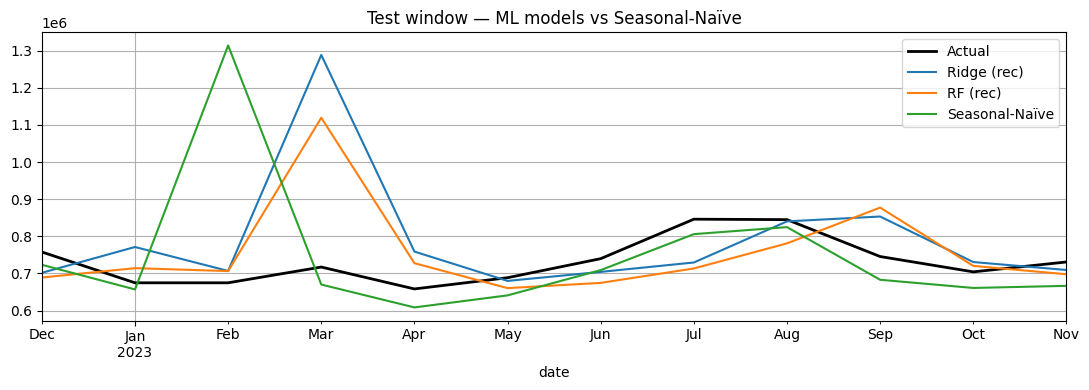

In [63]:
plot_forecast(
    test_y,
    {"Ridge (rec)": ridge_rec, "RF (rec)": rf_rec, "Seasonal-Naïve": snaive_t},
    title="Test window — ML models vs Seasonal-Naïve"
)
# plt.savefig("L5_test_cmp.png", dpi=140, bbox_inches="tight")


In [64]:
def rolling_origin_backtest(pipe, y: pd.Series, H: int, FE: dict,
                            columns_ref, n_folds=3, step=6, name="model"):
    """
    Make n_folds forecasts from earlier origins.
    step: months we move the origin back each fold (e.g., 6).
    """
    scores = []
    off = _get_offset(y.index)
    # Define cut points counting back from the end
    cut_points = [len(y) - (H + i*step) for i in range(n_folds, 0, -1)]
    for cut in cut_points:
        y_hist  = y.iloc[:cut]              # everything up to origin
        y_true  = y.iloc[cut:cut+H]         # next H months as pseudo-test
        y_pred  = recursive_forecast(pipe, y_hist, H, FE, columns_ref, name=name)
        y_pred.index = y_true.index         # align indices
        scores.append(score_forecast(y_true, y_pred, name))
    return pd.DataFrame(scores)

# Build full feature target y_all aligned to original y for origins
_, y_all_full = make_features(y, **FE)
# Use the same columns_ref as training
ridge_ro = rolling_origin_backtest(ridge_best, y_all_full, H, FE, train_X.columns, n_folds=3, step=6, name="Ridge (rec)")
rf_ro    = rolling_origin_backtest(rf_best,    y_all_full, H, FE, train_X.columns, n_folds=3, step=6, name="RF (rec)")

print("Rolling-origin (mean across folds):")
pd.concat([
    ridge_ro.assign(Fold="fold").mean(numeric_only=True).to_frame("Ridge (rec)"),
    rf_ro.assign(Fold="fold").mean(numeric_only=True).to_frame("RF (rec)")
], axis=1).round(3)


Rolling-origin (mean across folds):


,Ridge (rec),RF (rec)
MAE,134093.195,116698.576
RMSE,229896.330,198759.193
sMAPE%,15.698,13.937


In [65]:
def fit_predict(df_y: pd.Series, H=12, model="ridge", FE=None):
    """
    End-to-end: build features, split, tune, and forecast H months recursively.
    Returns (forecast_series, metrics_table).
    """
    assert model in {"ridge","rf"}
    FE = FE or dict(lags=(1,12), roll_windows=(3,12), add_month_onehot=True, add_month_cyc=True)

    X_all, y_all = make_features(df_y, **FE)
    (train_X, train_y), (val_X, val_y), (test_X, test_y) = split_after_fe(X_all, y_all, H=H, VAL=12)

    # Pipelines
    month_dummy_cols = [c for c in train_X.columns if c.startswith("m_")]
    num_cols = [c for c in train_X.columns if c not in month_dummy_cols]
    tscv = TimeSeriesSplit(n_splits=5)

    if model == "ridge":
        pre = ColumnTransformer([("num", StandardScaler(), num_cols),
                                 ("mon", "passthrough", month_dummy_cols)], remainder="drop")
        pipe = Pipeline([("pre", pre), ("model", Ridge(random_state=0))])
        grid = {"model__alpha": np.logspace(-3,3,7)}
    else:
        pre = ColumnTransformer([("all", "passthrough", train_X.columns.tolist())], remainder="drop")
        pipe = Pipeline([("pre", pre), ("model", RandomForestRegressor(
            random_state=42, n_estimators=300, n_jobs=-1))])
        grid = {"model__max_depth":[None,10], "model__min_samples_leaf":[1,3], "model__max_features":["sqrt",0.5]}

    cv = GridSearchCV(pipe, grid, cv=tscv, scoring="neg_mean_absolute_error", n_jobs=-1)
    cv.fit(train_X, train_y)
    best = cv.best_estimator_

    # Recursive forecast from end of Train+Val
    y_hist = pd.concat([train_y, val_y]) if val_y is not None else train_y
    y_pred = recursive_forecast(best, y_hist, H, FE, columns_ref=train_X.columns, name=f"{model.upper()} (rec)")

    # Baselines
    snaive = seasonal_naive_forecast(y_hist, H, m=12)
    naivef = naive_forecast(y_hist, H)

    metrics = pd.DataFrame([
        score_forecast(test_y, y_pred, f"{model.upper()} (rec)"),
        score_forecast(test_y, snaive, "Seasonal-Naïve"),
        score_forecast(test_y, naivef, "Naïve"),
    ]).round(3).set_index("Model")

    return y_pred, metrics


In [66]:
ridge_fc, ridge_metrics = fit_predict(y, H=12, model="ridge", FE=FE)
rf_fc,    rf_metrics    = fit_predict(y, H=12, model="rf",    FE=FE)

print("Ridge metrics:\n", ridge_metrics, "\n")
print("RF metrics:\n", rf_metrics)


Ridge metrics:
                       MAE        RMSE  sMAPE%
Model                                        
RIDGE (rec)     98125.731  177376.463  11.542
Seasonal-Naïve  91461.667  189286.353  10.774
Naïve           66699.167   87904.524   9.222 

RF metrics:
                       MAE        RMSE  sMAPE%
Model                                        
RF (rec)        90173.412  135162.586  11.245
Seasonal-Naïve  91461.667  189286.353  10.774
Naïve           66699.167   87904.524   9.222


Champion (Naïve) — Test metrics:
              MAE       RMSE  sMAPE%
Model                              
Naïve  66699.167  87904.524   9.222 



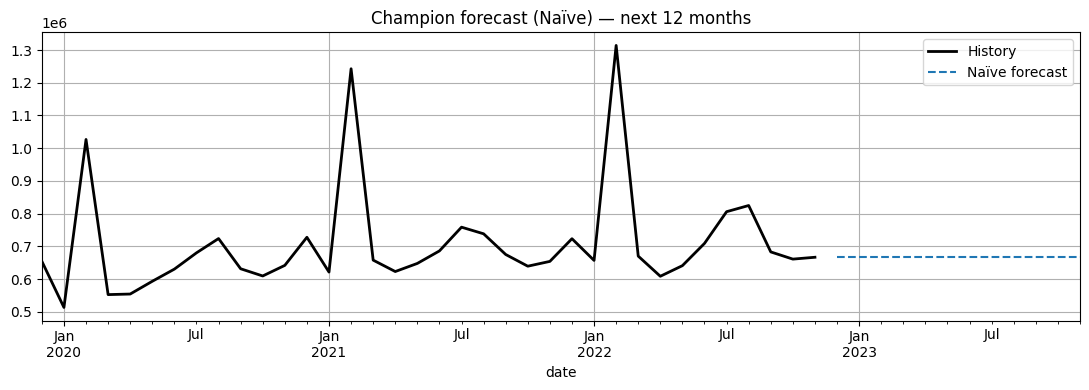

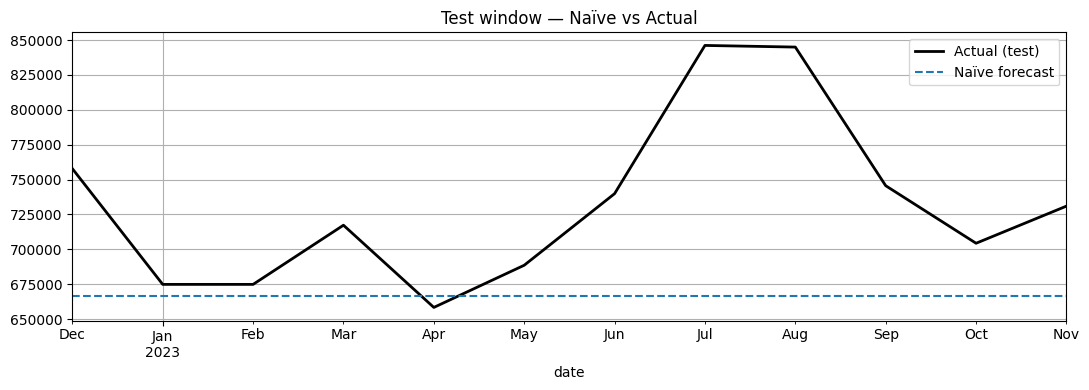

In [67]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pandas.tseries.frequencies import to_offset
from sklearn.metrics import mean_absolute_error

# --- Helpers (robust to missing .freq) ---
def _get_offset(idx: pd.DatetimeIndex):
    if idx.freq is not None: return idx.freq
    inf = pd.infer_freq(idx)
    if inf is not None: return to_offset(inf)
    if len(idx) >= 2:
        step = pd.Series(idx[1:] - idx[:-1]).mode().iloc[0]
        return to_offset(step)
    return to_offset("MS")

def naive_forecast(y_train: pd.Series, H: int) -> pd.Series:
    last = y_train.iloc[-1]; off = _get_offset(y_train.index)
    idx  = pd.date_range(y_train.index[-1] + off, periods=H, freq=off)
    return pd.Series(np.repeat(last, H), index=idx, name="Naïve")

def rmse(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    return float(np.sqrt(np.mean((y_true - y_pred)**2)))

def smape(y_true, y_pred, eps=1e-8):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    denom = np.maximum((np.abs(y_true) + np.abs(y_pred))/2, eps)
    return float(np.mean(np.abs(y_true - y_pred) / denom) * 100)

def score_forecast(y_true: pd.Series, y_pred: pd.Series, name: str) -> dict:
    y_true, y_pred = y_true.align(y_pred, join="inner")
    return {"Model": name,
            "MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": rmse(y_true, y_pred),
            "sMAPE%": smape(y_true, y_pred)}

# --- Rebuild split if needed ---
if 'H' not in globals(): H = 12
if 'VAL' not in globals(): VAL = 12

def time_splits(y: pd.Series, H=12, VAL=12):
    test = y.iloc[-H:]
    val  = y.iloc[-(H+VAL):-H] if VAL > 0 else None
    train = y.iloc[:-(H+VAL)] if VAL > 0 else y.iloc[:-H]
    return train, val, test

if 'train_y' not in globals() or 'test_y' not in globals():
    # If you only have the raw series y
    train_y, val_y, test_y = time_splits(y, H=H, VAL=VAL)

# --- Champion forecast (Naïve) ---
y_hist = pd.concat([train_y, val_y]) if val_y is not None else train_y
naive_fc = naive_forecast(y_hist, H)

# Metrics on the test window (confirmation)
metrics = pd.DataFrame([score_forecast(test_y, naive_fc, "Naïve")]).set_index("Model")
print("Champion (Naïve) — Test metrics:\n", metrics.round(3), "\n")

# --- Plot 1: Last 36 months + forecast ---
lookback = 36
y_tail = y_hist.iloc[-lookback:]
ax = y_tail.plot(label="History", color="black", lw=2)
naive_fc.plot(ax=ax, label="Naïve forecast", ls="--")
ax.set_title(f"Champion forecast (Naïve) — next {H} months")
ax.legend(); plt.tight_layout()
# plt.savefig("champion_naive_forecast_context.png", dpi=140, bbox_inches="tight")
plt.show()

# --- Plot 2: Test window only ---
ax = test_y.plot(label="Actual (test)", color="black", lw=2)
naive_fc.plot(ax=ax, label="Naïve forecast", ls="--")
ax.set_title("Test window — Naïve vs Actual")
ax.legend(); plt.tight_layout()
# plt.savefig("champion_naive_vs_actual_test.png", dpi=140, bbox_inches="tight")
plt.show()

# (Optional) Export forecast to CSV for hand-off
out = naive_fc.to_frame("forecast_naive")
# out.to_csv(f"forecast_naive_next_{H}m.csv", index=True)


What to do next (practical guidance)
- Add a seasonal baseline and compare: a Seasonal-Naïve (m=12) repeats last year’s month; it should track the summer peak better than plain Naïve. If its test sMAPE beats Naïve, make it your new champion.
- Model for risk, not just average error if peaks matter:
    - Evaluate pinball/quantile loss (e.g., P90/P95) or weighted RMSE that emphasizes summer months.
    - Produce prediction intervals (residual bootstrap or quantile regression) to communicate uncertainty.
- Richer features if you keep ML:
    - Month-of-year, fourier seasonal terms, holiday flags, weather/macros (if relevant).
    - Try XGBoost/LightGBM with those features, or SARIMA/Prophet as a strong classical seasonal baseline.
- Sanity checks:
    - Ensure the series has a set freq (.asfreq("MS")), no NA in the training window used for seasonal lags, and that you’re doing rolling-origin evaluation (you are).
    - Consider a log transform if variance grows with level.